# TP3 — regressão linear múltipla como diagnóstico estatístico

**Pergunta numérica:** quanto do comprimento da resposta de referência do Bitext pode ser explicado por características observáveis apenas na solicitação do cliente? O alvo é `len(response)`, em caracteres. Esta análise **não** prevê a intenção e não valida o classificador em português.

O corpus Bitext é inglês e híbrido/sintético. Reutilizamos as partições versionadas `train` e `test`; a partição `validation` fica intocada. Nenhum campo `response`, `intent`, `category` ou `tags` entra nas variáveis preditoras.

## 1. Ambiente, dados e verificações de integridade

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
DATASET = ROOT / 'data/processed/bitext_retail_intents.parquet'
REPORT_DIR = ROOT / 'reports/tp3_data'
FIGURE_DIR = REPORT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert DATASET.is_file(), 'Execute antes: python scripts/build_bitext_intent_dataset.py'
frame = pd.read_parquet(DATASET)
required = {'record_id', 'text', 'response', 'split', 'intent'}
assert required.issubset(frame.columns)
assert frame[list(required)].notna().all().all()
train = frame.loc[frame['split'].eq('train')].copy()
test = frame.loc[frame['split'].eq('test')].copy()
assert len(train) > 0 and len(test) > 0
assert not (set(train['text']) & set(test['text'])), 'Texto idêntico em treino e teste'
print(f'Corpus: {len(frame):,} | treino: {len(train):,} | teste: {len(test):,}')

Corpus: 44,884 | treino: 35,906 | teste: 4,489


## 2. Pré-processamento e modelo

São cinco variáveis numéricas da solicitação: caracteres, palavras, interrogações, exclamações e dígitos. O `StandardScaler` é ajustado **somente no treino** dentro do pipeline. A média do alvo no treino serve como referência ingênua. Caracteres e palavras podem ser colineares; os coeficientes não serão interpretados causalmente.

In [2]:
FEATURE_NAMES = ['request_chars', 'request_words', 'question_marks', 'exclamation_marks', 'digits']

def request_features(texts):
    clean = pd.Series(texts, copy=False).fillna('').astype(str)
    return pd.DataFrame({
        'request_chars': clean.str.len(),
        'request_words': clean.str.split().str.len(),
        'question_marks': clean.str.count(r'\?'),
        'exclamation_marks': clean.str.count('!'),
        'digits': clean.str.count(r'\d'),
    }, index=clean.index).astype(float)

X_train, X_test = train['text'], test['text']
y_train = train['response'].str.len().astype(float)
y_test = test['response'].str.len().astype(float)
assert y_train.ge(0).all() and y_test.ge(0).all()
model = Pipeline([
    ('features', FunctionTransformer(request_features, validate=False)),
    ('scale', StandardScaler()),
    ('regression', LinearRegression()),
])
model.fit(X_train, y_train)
baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(y_train), 1)), y_train)
predicted = model.predict(X_test)
baseline_predicted = baseline.predict(np.zeros((len(y_test), 1)))
residuals = y_test.to_numpy() - predicted
def metrics(actual, estimate):
    return {'r2': float(r2_score(actual, estimate)),
            'rmse_chars': float(np.sqrt(mean_squared_error(actual, estimate)))}
scores = {'linear_regression': metrics(y_test, predicted),
          'train_mean_baseline': metrics(y_test, baseline_predicted)}
pd.DataFrame(scores).T.round(4)

,r2,rmse_chars
linear_regression,0.0080,308.8243
train_mean_baseline,-0.0002,310.0979


## 3. Diagnóstico dos resíduos

No gráfico de resíduos, procuramos curvatura, dispersão não constante e valores extremos. O Q-Q plot confronta a distribuição dos resíduos com uma normal teórica; desvios das caudas limitam inferências baseadas em normalidade. Os gráficos usam apenas o teste e não alteram o ajuste.

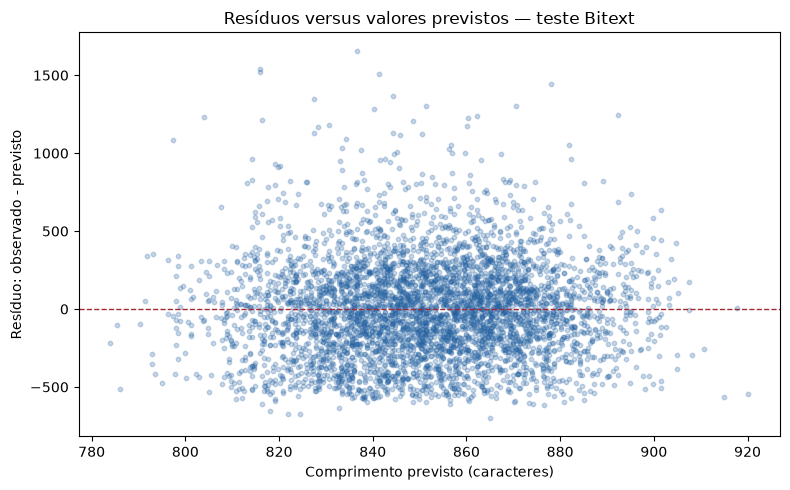

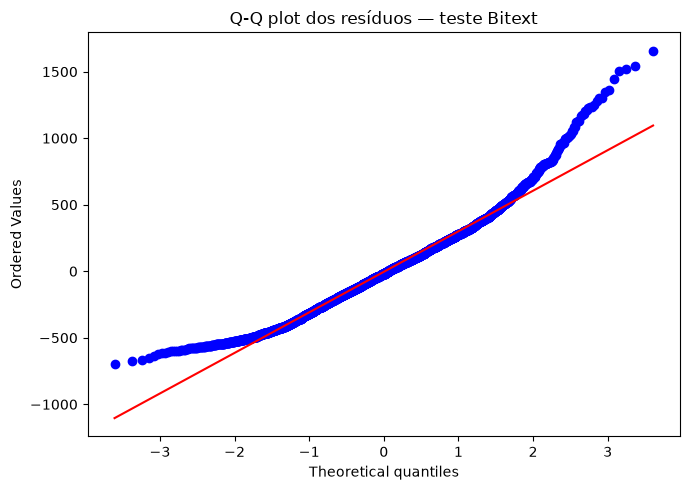

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(predicted, residuals, s=10, alpha=0.25, color='#2361a1')
ax.axhline(0, color='#a52834', linestyle='--', linewidth=1)
ax.set(xlabel='Comprimento previsto (caracteres)', ylabel='Resíduo: observado - previsto',
       title='Resíduos versus valores previstos — teste Bitext')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '01_residuos_vs_previsto.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(residuals, dist='norm', plot=ax)
ax.set_title('Q-Q plot dos resíduos — teste Bitext')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '02_qq_residuos.png', dpi=170)
plt.show()

In [4]:
coefficients = pd.Series(model.named_steps['regression'].coef_, index=FEATURE_NAMES)
diagnostics = {'residual_median': float(np.median(residuals)),
               'residual_p05': float(np.quantile(residuals, 0.05)),
               'residual_p95': float(np.quantile(residuals, 0.95))}
print('Coeficientes padronizados (descritivos, não causais):')
print(coefficients.round(3).to_string())
print('Resumo dos resíduos:', diagnostics)

Coeficientes padronizados (descritivos, não causais):
request_chars        -5.309
request_words        22.450
question_marks        7.324
exclamation_marks     0.000
digits                0.000
Resumo dos resíduos: {'residual_median': -19.678243487512646, 'residual_p05': -474.5478406433774, 'residual_p95': 519.1303166708545}


## 4. Limitações e próximos passos

No teste, R² = **0,0080** e RMSE = **308,82 caracteres**, contra **310,10** ao prever sempre a média do treino. A melhora de RMSE é de apenas **0,41%**; as variáveis explicam muito pouco da variação. As previsões se concentram em uma faixa estreita e os resíduos alcançam valores muito maiores. O Q-Q plot desvia claramente da reta na cauda superior, incompatível com uma aproximação normal simples dos resíduos.

- O alvo é comprimento da **resposta de referência** em um corpus inglês híbrido/sintético; não é tempo de atendimento, qualidade, sentimento ou intenção.
- O desenho é observacional. O modelo linear e seus coeficientes não estabelecem causalidade; a alta correlação entre caracteres e palavras pode tornar os coeficientes instáveis.
- Respostas padronizadas, assimetria, valores extremos e caudas não normais limitam o ajuste e a interpretação. O gráfico de resíduos também deve ser inspecionado quanto a padrões e dispersão variável, sem afirmar heterocedasticidade apenas pela aparência.
- A pergunta principal de T2 é **classificação multiclasse** de intenção, cujo alvo nominal não pode ser tratado como uma variável numérica contínua. O baseline candidato é TF-IDF + regressão logística; a amostra PT-BR anotada permanece fora do treinamento para avaliação externa futura.

In [5]:
result = {
    'dataset': 'bitext-retail-ecommerce-intents-v1',
    'target': 'response_length_chars',
    'features': FEATURE_NAMES,
    'train_rows': int(len(train)), 'test_rows': int(len(test)),
    'identical_texts_across_train_test': 0,
    'scores': scores, 'residual_summary': diagnostics,
    'model': 'StandardScaler + LinearRegression',
    'baseline': 'DummyRegressor(strategy=mean)',
}
(REPORT_DIR / 'regressao_linear_resultados.json').write_text(
    json.dumps(result, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
rmse_gain_pct = 100 * (scores['train_mean_baseline']['rmse_chars'] - scores['linear_regression']['rmse_chars']) / scores['train_mean_baseline']['rmse_chars']
(REPORT_DIR / 'regressao_linear.md').write_text(
    '# TP3 — regressão linear múltipla no Bitext\n\n'
    'Alvo: comprimento da resposta de referência, em caracteres. Preditores: apenas características da solicitação. '    'A partição de validação não foi usada.\n\n'
    f"Treino: {len(train):,} linhas; teste: {len(test):,} linhas; zero textos idênticos entre essas partições.\n\n"
    f"| Modelo | R² teste | RMSE teste (caracteres) |\n| --- | ---: | ---: |\n"
    f"| LinearRegression | {scores['linear_regression']['r2']:.4f} | {scores['linear_regression']['rmse_chars']:.2f} |\n"
    f"| Média do treino | {scores['train_mean_baseline']['r2']:.4f} | {scores['train_mean_baseline']['rmse_chars']:.2f} |\n\n"
    f"A melhora de RMSE sobre a média foi de apenas {rmse_gain_pct:.2f}%; o R² próximo de zero indica poder explicativo muito baixo. "
    'As previsões se concentram em faixa estreita e os resíduos têm cauda superior longa no Q-Q plot. '
    f"Mediana dos resíduos: {diagnostics['residual_median']:.2f}; percentis 5 e 95: {diagnostics['residual_p05']:.2f} e {diagnostics['residual_p95']:.2f} caracteres. "
    'Ver [resíduos versus previsto](figures/01_residuos_vs_previsto.png) e [Q-Q plot](figures/02_qq_residuos.png).\n\n'
    '## Limitações\n\nO Bitext é inglês e híbrido/sintético; comprimento de resposta não equivale a intenção. '
    'Colinearidade entre medidas de extensão, assimetria e cauda não normal limitam inferência. '
    'A regressão não substitui a classificação supervisionada e não mede desempenho em PT-BR.\n',
    encoding='utf-8')
print('Relatório e figuras salvos em', REPORT_DIR.relative_to(ROOT))

Relatório e figuras salvos em reports/tp3_data
